In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 解决中文显示问题
plt.rcParams['font.sans-serif'] = ['SimHei']  # Windows系统用黑体
plt.rcParams['axes.unicode_minus'] = False 

D:\ApowerREC\lib\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
# 1. 读取数据
file_path = '各地级市数字产业聚集水平1990-2023年.xlsx' 
df = pd.read_excel(file_path)

# 2. 清洗列名（去除换行符和空格）
df.columns = df.columns.str.replace('\n', '').str.strip()

# 3. 格式转换
df['年份'] = pd.to_numeric(df['年份'], errors='coerce')
df['数字产业聚集水平'] = pd.to_numeric(df['数字产业聚集水平'], errors='coerce')

# 4. 剔除已撤销的城市（巢湖、莱芜）
df = df[~df['城市'].isin(['巢湖市', '莱芜市'])]

# 5. 缺失值插补（按城市分组，线性插值）
df['数字产业聚集水平'] = df.groupby('城市')['数字产业聚集水平'].transform(
    lambda x: x.interpolate(method='linear', limit_direction='both')
)

# 6. 剔除仍有缺失的行
df = df.dropna(subset=['数字产业聚集水平'])

print("数据清洗完成！数据共有", len(df), "行。")

数据清洗完成！数据共有 10098 行。


D:\ApowerREC\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
D:\ApowerREC\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
D:\ApowerREC\lib\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
D:\ApowerREC\lib\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pan

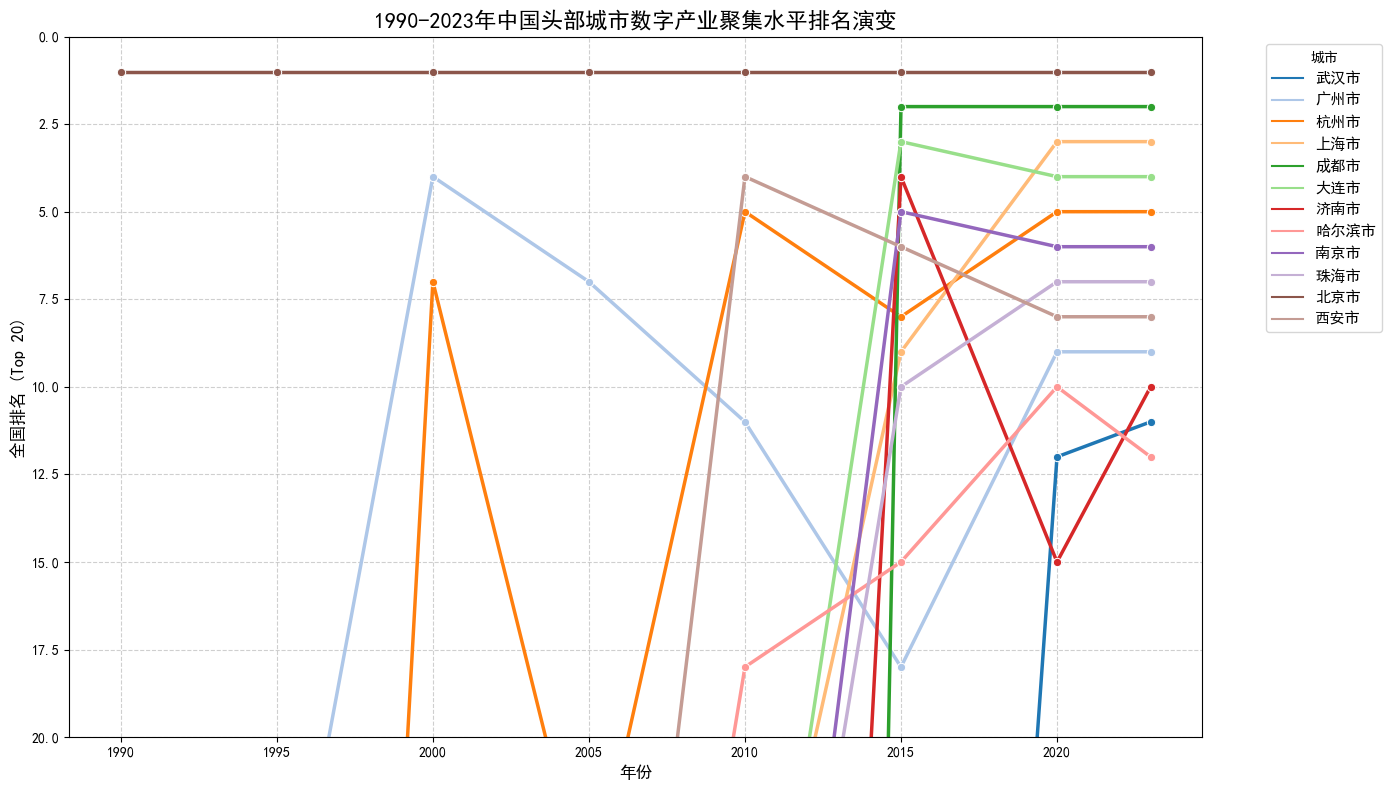

In [3]:
# ==========================================
# 优化版：只追踪 2023 年 Top 12 城市的排名演变
# ==========================================

years_to_plot = [1990, 1995, 2000, 2005, 2010, 2015, 2020, 2023]
df_filtered = df[df['年份'].isin(years_to_plot)].copy()

# 计算每年的排名
df_filtered['排名'] = df_filtered.groupby('年份')['数字产业聚集水平'].rank(ascending=False, method='min')

# 【核心修改点】只选出 2023 年排名前 12 的城市
top_12_cities_2023 = df_filtered[df_filtered['年份'] == 2023].nsmallest(12, '排名')['城市'].unique()

# 筛选出这 12 个城市的历史数据
df_top12 = df_filtered[df_filtered['城市'].isin(top_12_cities_2023)]

# 开始绘图
plt.figure(figsize=(14, 8))
# 使用高对比度的调色板
sns.lineplot(data=df_top12, x='年份', y='排名', hue='城市', marker='o', linewidth=2.5, palette='tab20')

# 反转 Y 轴（第1名在最上面）
plt.gca().invert_yaxis()

# 【核心修改点】限制 Y 轴的显示范围。
# 只显示第 1 到 20 名，哪怕某些城市当年排第 100 名，线条也只会画到 20 的位置，保持画面干净。
plt.ylim(20, 0)

plt.title('1990-2023年中国头部城市数字产业聚集水平排名演变', fontsize=16, fontweight='bold')
plt.xlabel('年份', fontsize=12)
plt.ylabel('全国排名 (Top 20)', fontsize=12)

# 将图例移到图外，依然保持整洁
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='城市', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('Top10_Bump_Chart.png', dpi=300)
plt.show()

D:\ApowerREC\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
D:\ApowerREC\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
D:\ApowerREC\lib\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


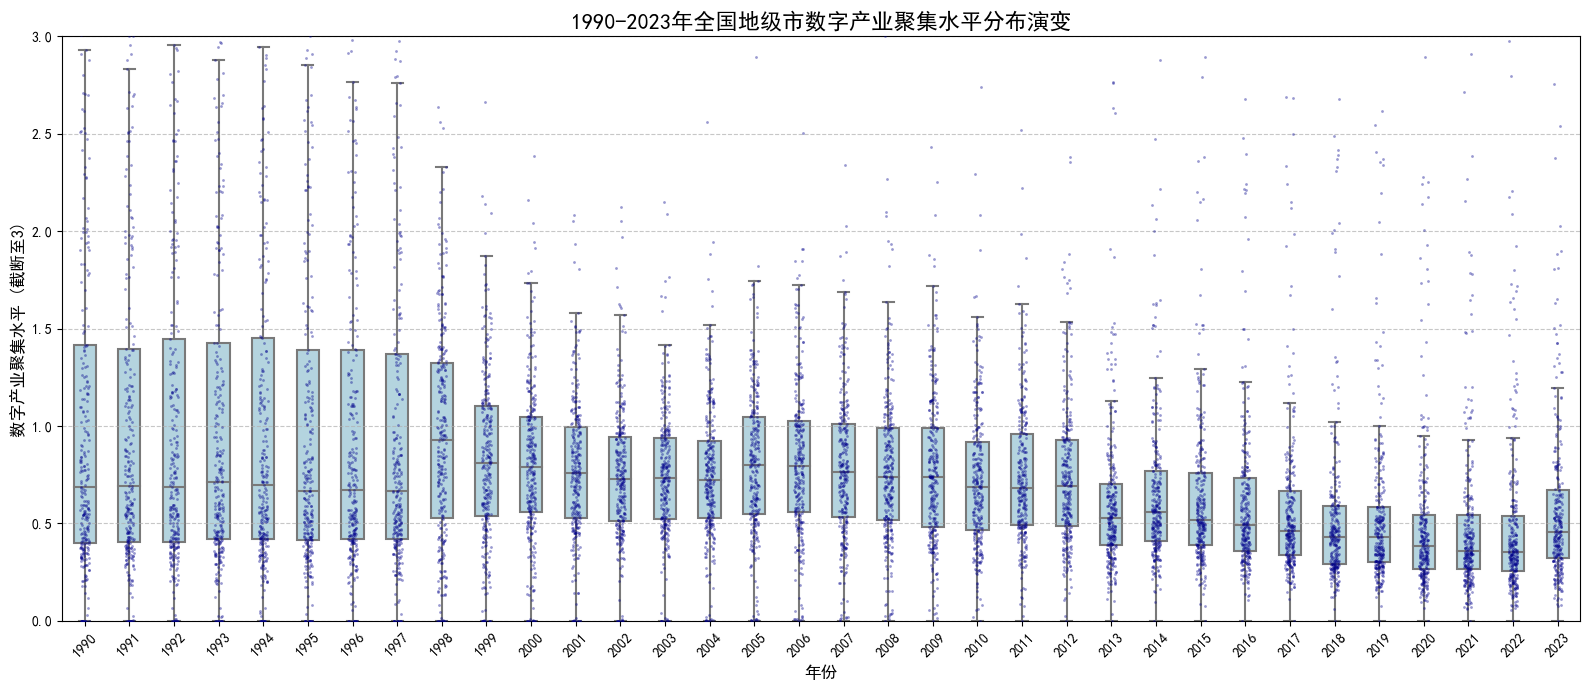

In [4]:
# ==========================================
# 板块 4：生成聚集水平分布变化图 (箱线图 + 散点)
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(16, 7))

# 1. 绘制箱线图
# 原理：箱线图展示了数据的分布规律。中间的横线是中位数，箱子的上下边缘是25%和75%的分位数。
# outlierprops 设置为透明，是因为我们要在上面叠加真实的数据散点，避免异常点重复显示。
sns.boxplot(data=df, x='年份', y='数字产业聚集水平', 
            color='lightblue', width=0.5, 
            showfliers=False)

# 2. 叠加散点图 (Stripplot)
# 原理：为了看清真实城市的分布，在箱子上加上小点（jitter=True 让小点左右抖动，避免重叠）。
# alpha=0.5 设置透明度，size=2 设置点的大小。
sns.stripplot(data=df, x='年份', y='数字产业聚集水平', 
              color='darkblue', size=2, alpha=0.4, jitter=True)

# 3. 限制 Y 轴范围（核心）
# 问题：因为北京等城市数值极高（如1990年的23.7），如果不截断，图表会被拉得非常长，看不清下面的箱子。
# 解决：截取 0 到 3 的区间（大约包含了 95% 的正常城市样本，超过 3 的极端值被隐藏，以突出重点）。
plt.ylim(0, 3)

# 4. 设置标题和标签
plt.title('1990-2023年全国地级市数字产业聚集水平分布演变', fontsize=16, fontweight='bold')
plt.xlabel('年份', fontsize=12)
plt.ylabel('数字产业聚集水平 (截断至3)', fontsize=12)

# 5. X轴标签旋转，防止年份重叠
plt.xticks(rotation=45)

# 6. 添加网格线
plt.grid(axis='y', linestyle='--', alpha=0.7)

# 7. 保存并展示
plt.tight_layout()
plt.savefig('Distribution_Boxplot.png', dpi=300)
plt.show()